# Multi-Sheet Macroeconomic & Nowcasting Models: GDP, Inflation Rate, and CPI
**Group Project Pipeline**

This notebook combines information from multiple sheets in the Bangladesh Bank Excel workbook (`Apr26 (For Shounok 16.07.2026).xlsx`):
- **Table IXC:** Quarterly Gross Domestic Product (aggregated to annual fiscal GDP)
- **Table IB:** Consumer Price Index (CPI), 12-Month Average Inflation Rate, Industrial Production, Imports, Foreign Exchange Reserves, and Exchange Rates
- **Table IV:** Merchandise Exports

**Targets (in order of priority):**
1. **GDP** (Nominal GDP, Taka in Crore)
2. **Inflation Rate** (12-Month Average Inflation %, Base: 2021-22 and 2005-06)
3. **CPI** (Point-to-Point Consumer Price Index)

**Baseline Models:** Linear Regression, Decision Tree Regressor, and K-Nearest Neighbors (KNN) Regressor.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Workbook and Sheets

In [2]:
file_path = 'Apr26 (For Shounok 16.07.2026).xlsx'
excel_file = pd.ExcelFile(file_path)

print('Number of sheets:', len(excel_file.sheet_names))
print('Sheet names preview:', excel_file.sheet_names[:10])

t_ixc_raw = pd.read_excel(file_path, sheet_name='TableIXC', header=None)
t_ib_raw = pd.read_excel(file_path, sheet_name='Table IB', header=None)
t_iv_raw = pd.read_excel(file_path, sheet_name='Table IV', header=None)

Number of sheets: 45
Sheet names preview: ['Cover Page', 'Contents', 'Table IA', 'Table IB', 'TableIIA', 'TableIIB', 'TableIIC ', 'Table IID', 'Table IIE', 'Table IIF']


## 3. Data Preprocessing & Feature Extraction

In [3]:
# 3.1 Extract and Aggregate Annual GDP from Table IXC
gdp_q = t_ixc_raw.iloc[6:58, [0, 1, 17]].copy()
gdp_q.columns = ['FY', 'Qtr', 'GDP']
gdp_q['FY_clean'] = gdp_q['FY'].astype(str).str.replace('P','', regex=False).str.replace('p','', regex=False)
gdp_q['GDP'] = pd.to_numeric(gdp_q['GDP'], errors='coerce')

annual_gdp = gdp_q.dropna(subset=['GDP']).groupby('FY_clean')['GDP'].sum().reset_index()
display(annual_gdp.head())

,FY_clean,GDP
0,2015-16,2075820.0
1,2016-17,2324307.0
2,2017-18,2639246.0
3,2018-19,2951429.0
4,2019-20,3170468.0


In [4]:
# 3.2 Extract Inflation, CPI, and Macro Indicators from Table IB
ann_ib = t_ib_raw.iloc[8:44, [0, 1, 2, 3, 4, 5, 9, 11, 12, 14]].copy()
ann_ib.columns = ['Period', 'Month', 'Point_New', 'Point_Old', 'Avg_New', 'Avg_Old', 'TotalInd', 'Imports', 'Forex', 'ExchAvg']
ann_ib = ann_ib[ann_ib['Month'].isna() & ann_ib['Period'].astype(str).str.match(r'^\d{4}-\d{2}P?$', na=False)].copy()

ann_ib['FY_clean'] = ann_ib['Period'].str.replace('P','', regex=False)
for c in ['Point_New', 'Point_Old', 'Avg_New', 'Avg_Old', 'TotalInd', 'Imports', 'Forex', 'ExchAvg']:
    ann_ib[c] = pd.to_numeric(ann_ib[c].astype(str).str.replace('\xa0','', regex=False).str.replace(',','', regex=False).str.replace('…','nan', regex=False), errors='coerce')

ann_ib['Inflation_Rate'] = ann_ib['Avg_New'].fillna(ann_ib['Avg_Old'])
ann_ib['CPI'] = ann_ib['Point_New'].fillna(ann_ib['Point_Old'])
macro_data = ann_ib[['FY_clean', 'Inflation_Rate', 'CPI', 'TotalInd', 'Imports', 'Forex', 'ExchAvg']]
display(macro_data.head())

,FY_clean,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg
8,1994-95,NaN,NaN,83.0,3472.5,5834.0,NaN
9,1995-96,NaN,NaN,79.0,3882.4,6931.0,NaN
10,1996-97,3.96,NaN,80.0,4418.3,7152.0,NaN
11,1997-98,8.66,NaN,81.0,5161.2,7520.0,NaN
12,1998-99,7.06,NaN,72.0,5312.8,8006.0,NaN


In [5]:
# 3.3 Extract Merchandise Exports from Table IV
ann_4 = t_iv_raw.iloc[9:45].copy()
ann_4 = ann_4[ann_4[0].astype(str).str.match(r'^\d{4}-\d{2}$', na=False)].copy()
ann_4['FY_clean'] = ann_4[0].astype(str)
ann_4['Exports'] = pd.to_numeric(ann_4[12].astype(str).str.replace('\xa0','', regex=False).str.replace(',','', regex=False), errors='coerce')
exports_data = ann_4[['FY_clean', 'Exports']]

# 3.4 Merge All Sheets into a Unified Panel Dataset
df = annual_gdp.merge(macro_data, on='FY_clean', how='inner') \
               .merge(exports_data, on='FY_clean', how='inner').dropna().reset_index(drop=True)
display(df.head())

,FY_clean,GDP,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg,Exports
0,2015-16,2075820.0,5.920000,5.53,100.000000,43122.5,30355.56,78.268600,236803.1
1,2016-17,2324307.0,5.440000,5.94,110.685356,47005.2,33679.38,79.133000,239656.2
2,2017-18,2639246.0,5.780000,5.54,125.719552,58865.3,32943.46,82.107700,267179.8
3,2018-19,2951429.0,5.480000,5.52,143.889228,59914.6,32716.51,84.020800,296983.9
4,2019-20,3170468.0,5.647611,6.02,145.071764,54784.8,36037.03,84.781146,265453.5


## 4. Exploratory Data Analysis (EDA)

                GDP  Inflation_Rate       CPI    TotalInd       Imports  \
count  8.000000e+00        8.000000  8.000000    8.000000      8.000000   
mean   3.144251e+06        6.124701  6.436250  145.831766  61688.875000   
std    8.240738e+05        1.193738  1.497388   33.756478  14966.542665   
min    2.075820e+06        5.440000  5.520000  100.000000  43122.500000   
25%    2.560511e+06        5.540000  5.537500  121.961003  52839.900000   
50%    3.060948e+06        5.713806  5.790000  144.480496  59389.950000   
75%    3.640567e+06        5.977500  6.405000  166.833674  67961.425000   
max    4.490835e+06        9.020000  9.740000  197.390000  89162.300000   

              Forex     ExchAvg        Exports  
count      8.000000    8.000000       8.000000  
mean   35644.138721   85.678368  300359.387500  
std     5622.671083    8.659508   69010.729119  
min    30355.560000   78.268600  236803.100000  
25%    32338.132500   81.364025  259004.175000  
50%    33311.420000   84.40097

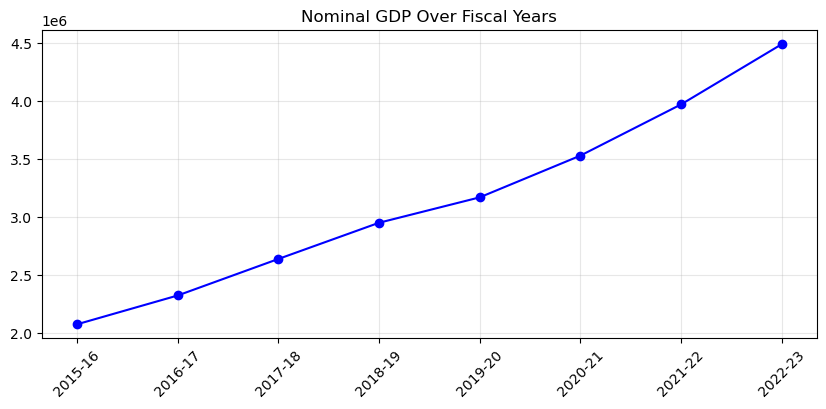

In [6]:
print(df.describe())

plt.figure(figsize=(10, 4))
plt.plot(df['FY_clean'], df['GDP'], marker='o', color='b')
plt.title('Nominal GDP Over Fiscal Years')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

## 5. Modeling Pipeline for Priority Targets

In [7]:
targets = ['GDP', 'Inflation_Rate', 'CPI']
all_features = [c for c in df.columns if c not in ['FY_clean'] + targets]

for target in targets:
    print(f'\n=== MODELING FOR TARGET: {target} ===')
    other_targets = [t for t in targets if t != target]
    X = df[all_features + other_targets]
    y = df[target]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    lr = LinearRegression().fit(X_train, y_train)
    dt = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
    knn = KNeighborsRegressor(n_neighbors=2).fit(X_train_scaled, y_train)
    
    res = pd.DataFrame({
        'Model': ['Linear Regression', 'Decision Tree', 'KNN'],
        'MAE': [mean_absolute_error(y_test, lr.predict(X_test)),
                  mean_absolute_error(y_test, dt.predict(X_test)),
                  mean_absolute_error(y_test, knn.predict(X_test_scaled))],
        'RMSE': [np.sqrt(mean_squared_error(y_test, lr.predict(X_test))),
                   np.sqrt(mean_squared_error(y_test, dt.predict(X_test))),
                   np.sqrt(mean_squared_error(y_test, knn.predict(X_test_scaled)))],
        'R2 Score': [r2_score(y_test, lr.predict(X_test)),
                     r2_score(y_test, dt.predict(X_test)),
                     r2_score(y_test, knn.predict(X_test_scaled))]
    })
    display(res.round(4))


=== MODELING FOR TARGET: GDP ===


,Model,MAE,RMSE,R2 Score
0,Linear Regression,225372.6136,267956.1218,0.8025
1,Decision Tree,712458.0000,724895.0917,-0.4455
2,KNN,37067.2500,37265.7514,0.9962



=== MODELING FOR TARGET: Inflation_Rate ===


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.4611,0.5680,-88.6322
1,Decision Tree,0.2838,0.3450,-32.0661
2,KNN,0.3744,0.3761,-38.2902



=== MODELING FOR TARGET: CPI ===


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.7706,0.8886,-34.0938
1,Decision Tree,0.3950,0.3953,-5.9444
2,KNN,0.7775,0.8621,-32.0339
